# AI Model Experiment & Evaluation
**Sentiment analysis ulasan e-commerce: Classic ML (TF-IDF + Logistic Regression) vs LLM lokal (Ollama `gpt-oss:20b`)**

Notebook ini mengikuti alur assignment: **Prepare → Experiment → Evaluate → Recommend**.

| Bagian | Isi |
|---|---|
| 0 | Setup & konfigurasi |
| 1 | Prepare: muat dataset & cek kualitas data |
| 2 | Split data 80:20 dengan `StratifiedGroupKFold` (beserta alasannya) |
| 3 | Eksperimen 1: TF-IDF + Logistic Regression (+ 5-fold CV untuk cek kestabilan) |
| 4 | Eksperimen 2: LLM `gpt-oss:20b` via Ollama (few-shot prompting) |
| 5 | Evaluasi & perbandingan (metrik, confusion matrix, tabel ringkasan) |
| 6 | Analisis trade-off & limitation |
| 7 | Rekomendasi technical approach |

## 0. Setup & Konfigurasi
Semua angka acak dikunci dengan `RANDOM_STATE = 42` supaya hasilnya **bisa diulang** (siapa pun yang menjalankan akan dapat angka yang sama).

In [2]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

try:
    from IPython.display import display
except ImportError:          # supaya sel tetap jalan kalau dijalankan di luar Jupyter
    display = print

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
LABELS = ["negatif", "positif"]      # urutan label dikunci (dipakai di confusion matrix & metrik)

# Lokasi project: bisa dijalankan dari root project ATAU dari folder notebook/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH   = ROOT / "data" / "customer_reviews_sentiment.csv"
RESULTS_DIR = ROOT / "results"
DOC_DIR     = ROOT / "documentation"
RESULTS_DIR.mkdir(exist_ok=True)
DOC_DIR.mkdir(exist_ok=True)

# Konfigurasi LLM (Ollama, jalan lokal)
OLLAMA_MODEL    = "gpt-oss:20b"
LLM_TEMPERATURE = 0                  # 0 = jawaban paling konsisten (cocok untuk klasifikasi)
LLM_SEED        = 42
FORCE_RERUN_LLM = False              # True = abaikan cache & panggil Ollama ulang
LLM_CACHE       = RESULTS_DIR / "llm_predictions.csv"

print("Project root:", ROOT)

Project root: /Users/fbrynmghni/Code/AI Engineering/model-experiment-assignment


## 1. Prepare: Muat Dataset & Cek Kualitas Data
Dataset **hanya dibaca**, tidak diubah (file asli di `data/` tetap utuh). Karena tidak ada missing value, kita tidak butuh data cleaning. Tapi kita tetap cek **duplikat**, karena duplikat memengaruhi cara kita membagi data.

In [3]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

print("\nDistribusi label:")
display(df["sentiment"].value_counts().to_frame("jumlah")
        .assign(persen=lambda d: (d["jumlah"] / len(df) * 100).round(1)))

print("Missing value per kolom:")
print(df.isna().sum().to_string())

Shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif



Distribusi label:


,jumlah,persen
sentiment,,
positif,110,55.0
negatif,90,45.0


Missing value per kolom:
review_id       0
product_name    0
review_text     0
sentiment       0


In [4]:
n_unique = df["review_text"].nunique()
print(f"Total baris: {len(df)} | Teks unik: {n_unique} | Baris duplikat: {len(df) - n_unique}")

# Apakah ada teks yang sama tapi labelnya berbeda? (kalau ada, labelnya tidak konsisten)
konflik = (df.groupby("review_text")["sentiment"].nunique() > 1).sum()
print("Teks dengan label bertentangan:", konflik)

print("\n5 teks yang paling sering muncul:")
display(df["review_text"].value_counts().head(5).to_frame("muncul_berapa_kali"))

Total baris: 200 | Teks unik: 40 | Baris duplikat: 160
Teks dengan label bertentangan: 0

5 teks yang paling sering muncul:


,muncul_berapa_kali
review_text,
"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",12
"Produknya rapi dan bersih, tidak ada cacat sama sekali.",9
"Pengiriman lambat sekali, sudah dua minggu belum sampai.",8
"Kualitas produk jelek, baru dipakai sekali sudah rusak.",8
"Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.",8


**Temuan:** dataset punya 200 baris tapi hanya **40 teks unik** (20 positif + 20 negatif). Label-nya konsisten (tidak ada teks yang punya dua label berbeda). Artinya, kalau kita asal membagi data secara acak, kalimat yang **sama persis** bisa masuk ke train **dan** test. Ini kita tangani di bagian berikutnya.

## 2. Split Data 80:20 dengan `StratifiedGroupKFold`

### Alasan memakai `StratifiedGroupKFold` (bukan `train_test_split` biasa)

1. **Dataset kecil dan penuh duplikat.** 200 baris, tapi cuma 40 teks unik.
2. **`train_test_split(stratify=y)` hanya menjaga proporsi label**, tidak peduli teks duplikat. Akibatnya kalimat yang sama muncul di train dan test (**data leakage**). Model tinggal "menghafal" kalimat itu, jadi skornya terlihat bagus padahal belum tentu pintar.
   - *Analogi:* murid latihan pakai soal A, B, C, lalu ujiannya pakai soal A, B, C juga. Nilainya bagus, tapi itu bukan ukuran kemampuan sebenarnya.
3. **`StratifiedGroupKFold` menyelesaikan dua hal sekaligus:**
   - **Group** (`groups = review_text`): semua baris dengan teks yang sama **selalu berada di sisi yang sama** (semuanya di train atau semuanya di test).
   - **Stratified**: proporsi positif/negatif tetap dijaga, sama seperti `stratify=y`.
4. **`n_splits=5` ≈ pembagian 80:20.** Satu fold dipakai sebagai **test set (~20%)**, sisanya (~80%) jadi **train set**. `shuffle=True` + `random_state=42` membuat pembagian acak tapi bisa diulang.
5. **Test set yang sama** dipakai untuk kedua pendekatan (Classic ML dan LLM), jadi perbandingannya adil.

Pertama kita buktikan dulu bahwa split biasa memang bocor:

In [5]:
# DEMONSTRASI saja (tidak dipakai untuk evaluasi resmi): split biasa dengan stratify=y
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    df["review_text"], df["sentiment"], test_size=0.2, stratify=df["sentiment"], random_state=RANDOM_STATE)

bocor = int(Xa_te.isin(set(Xa_tr)).sum())
print(f"[Split biasa] baris test yang teksnya JUGA ada di train: {bocor} dari {len(Xa_te)}")

[Split biasa] baris test yang teksnya JUGA ada di train: 39 dari 40


In [6]:
X, y, groups = df["review_text"], df["sentiment"], df["review_text"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups))      # fold pertama = test set (~20%)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df  = df.iloc[test_idx].reset_index(drop=True)

# Pastikan tidak ada kalimat yang sama di train dan test
overlap = set(train_df["review_text"]) & set(test_df["review_text"])
assert len(overlap) == 0, "Ada kebocoran: teks yang sama muncul di train dan test!"

ringkasan = pd.DataFrame({
    "baris":     [len(train_df), len(test_df)],
    "teks_unik": [train_df["review_text"].nunique(), test_df["review_text"].nunique()],
    "positif":   [(train_df["sentiment"] == "positif").sum(), (test_df["sentiment"] == "positif").sum()],
    "negatif":   [(train_df["sentiment"] == "negatif").sum(), (test_df["sentiment"] == "negatif").sum()],
}, index=["train", "test"])
ringkasan["persen_baris"]   = (ringkasan["baris"] / len(df) * 100).round(1)
ringkasan["persen_positif"] = (ringkasan["positif"] / ringkasan["baris"] * 100).round(1)
display(ringkasan)
print("Teks yang sama di train & test:", len(overlap), "(harus 0)")

,baris,teks_unik,positif,negatif,persen_baris,persen_positif
train,160,32,88,72,80.0,55.0
test,40,8,22,18,20.0,55.0


Teks yang sama di train & test: 0 (harus 0)


`persen_baris` mendekati 80/20, `persen_positif` di train dan test mendekati proporsi dataset asli (55%), dan overlap teks = 0. Berarti split-nya **bersih dan seimbang**.

## 3. Eksperimen 1: Model Klasik (TF-IDF + Logistic Regression)

**Gambaran sederhana:**
- **TF-IDF** mengubah teks jadi angka. Kata yang sering muncul di satu ulasan tapi jarang di ulasan lain diberi bobot tinggi. Contoh: "kecewa" bobotnya tinggi (jarang muncul, sangat informatif), sedangkan "yang" bobotnya rendah (ada di mana-mana).
- `ngram_range=(1, 2)` artinya model melihat kata tunggal **dan** pasangan kata. Jadi "tidak puas" dipahami berbeda dari "puas".
- **Logistic Regression** mengambil angka-angka itu lalu menghitung peluang: "ulasan ini positif atau negatif?"

Keduanya dibungkus dalam satu `Pipeline`. Ini penting: saat cross-validation, TF-IDF akan di-*fit* **hanya pada data train di tiap fold**. Kalau TF-IDF di-fit di seluruh data dulu, itu juga kebocoran.

In [7]:
def make_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2))),
        ("clf",   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

print(make_pipeline())

Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])


### 3a. Cek kestabilan: 5-fold `StratifiedGroupKFold` CV (hanya pada train set)
Test set **dikunci** dan tidak disentuh di tahap ini. CV dipakai untuk melihat apakah performa model **stabil** antar-fold. Kalau skornya naik-turun jauh, hasil di test set tidak bisa dipercaya begitu saja.

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}

cv_res = cross_validate(make_pipeline(), train_df["review_text"], train_df["sentiment"],
                        groups=train_df["review_text"], cv=cv, scoring=scoring)

cv_table = pd.DataFrame({k.replace("test_", ""): v for k, v in cv_res.items() if k.startswith("test_")})
cv_table.index = [f"fold {i + 1}" for i in range(len(cv_table))]
display(cv_table.round(3))

cv_summary = cv_table.agg(["mean", "std"]).round(3)
print("Ringkasan CV (mean dan standar deviasi antar-fold):")
display(cv_summary)
cv_summary.to_csv(RESULTS_DIR / "classic_cv_summary.csv")

,accuracy,precision,recall,f1
fold 1,0.455,0.469,0.470,0.454
fold 2,0.394,0.396,0.411,0.380
fold 3,0.531,0.266,0.500,0.347
fold 4,0.806,0.870,0.786,0.789
fold 5,0.839,0.886,0.821,0.827


Ringkasan CV (mean dan standar deviasi antar-fold):


,accuracy,precision,recall,f1
mean,0.605,0.577,0.598,0.559
std,0.205,0.284,0.191,0.231


`mean` = rata-rata skor di 5 fold. `std` = seberapa naik-turun skornya. `std` kecil berarti model **stabil**. **Catatan**: train set cuma punya sekitar 32 teks unik, jadi tiap fold validasi hanya berisi sekitar 6-7 teks unik. Fold sekecil itu membuat skor mudah naik-turun, jadi baca angka CV sebagai **indikasi kestabilan**, bukan angka final.

### 3b. Latih di seluruh train set, lalu prediksi test set

In [9]:
t0 = time.perf_counter()
classic_model = make_pipeline().fit(train_df["review_text"], train_df["sentiment"])
classic_train_s = time.perf_counter() - t0

t0 = time.perf_counter()
test_df["classic_pred"] = classic_model.predict(test_df["review_text"])
classic_infer_ms = (time.perf_counter() - t0) / len(test_df) * 1000

test_df[["review_id", "review_text", "sentiment", "classic_pred"]].to_csv(
    RESULTS_DIR / "classic_predictions.csv", index=False)

print(f"Waktu training : {classic_train_s:.3f} detik")
print(f"Inferensi      : {classic_infer_ms:.3f} ms per ulasan")
display(test_df[["review_text", "sentiment", "classic_pred"]].head(8))

Waktu training : 0.007 detik
Inferensi      : 0.034 ms per ulasan


,review_text,sentiment,classic_pred
0,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif
1,"Belanja disini selalu puas, kualitas terjaga.",positif,positif
2,"Barang yang datang tidak sesuai dengan foto, k...",negatif,negatif
3,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif
4,"Sudah langganan di toko ini, kualitas selalu k...",positif,positif
5,"Bahan murahan, tidak sesuai dengan harga yang ...",negatif,positif
6,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif
7,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif


In [10]:
# Sanity check: kenapa split biasa menyesatkan? (hanya demonstrasi)
leaky_model = make_pipeline().fit(Xa_tr, ya_tr)
acc_bocor  = accuracy_score(ya_te, leaky_model.predict(Xa_te))
acc_bersih = accuracy_score(test_df["sentiment"], test_df["classic_pred"])
print(f"Akurasi di split BIASA (bocor)            : {acc_bocor:.3f}")
print(f"Akurasi di split GROUP (bersih, dipakai)  : {acc_bersih:.3f}")

Akurasi di split BIASA (bocor)            : 1.000
Akurasi di split GROUP (bersih, dipakai)  : 0.625


## 4. Eksperimen 2: LLM `gpt-oss:20b` via Ollama (Few-shot Prompting)

**Gambaran sederhana:** model klasik harus *dilatih* dulu. LLM tidak: kita cukup **memberi instruksi (prompt)** plus beberapa contoh, lalu LLM langsung menjawab.

### Desain prompt
- **System prompt**: menjelaskan peran LLM dan format jawaban ("jawab HANYA satu kata: positif atau negatif"). Format ketat memudahkan kita membaca jawabannya.
- **Few-shot**: 6 contoh (3 positif + 3 negatif) yang diambil **dari train set saja**. Contoh tidak boleh diambil dari test set, kalau tidak LLM "mengintip" jawaban.

### Parameter dan alasannya
| Parameter | Nilai | Alasan |
|---|---|---|
| `temperature` | `0` | Klasifikasi butuh jawaban yang konsisten, bukan kreatif. Temperature 0 membuat LLM selalu memilih jawaban paling mungkin. |
| `seed` | `42` | Supaya hasilnya bisa diulang. |
| `think` | `"low"` | `gpt-oss` adalah model *reasoning*. Level `low` membatasi "berpikir panjang" supaya lebih cepat; tugas ini sederhana. |
| `num_predict` | `1024` | Batas token. Token "berpikir" ikut dihitung, jadi jangan terlalu kecil (kalau terpotong, jawabannya kosong). |

### Jawaban `invalid`
LLM kadang menjawab di luar format (kosong, ambigu, atau bertele-tele). Jawaban seperti itu kita tandai **`invalid`** dan dihitung **salah**. Jumlahnya dilaporkan terpisah.

In [11]:
# Few-shot: 3 positif + 3 negatif dari TRAIN saja (teks unik), dipilih reproducible
uniq_train = train_df.drop_duplicates("review_text")
shots = pd.concat([
    uniq_train[uniq_train["sentiment"] == "positif"].sample(3, random_state=RANDOM_STATE),
    uniq_train[uniq_train["sentiment"] == "negatif"].sample(3, random_state=RANDOM_STATE),
]).sample(frac=1, random_state=RANDOM_STATE)          # acak urutan supaya tidak berpola

SYSTEM_PROMPT = (
    "Kamu adalah classifier sentimen untuk ulasan produk e-commerce berbahasa Indonesia. "
    "Tentukan apakah ulasan bernada 'positif' atau 'negatif'. "
    "Jawab HANYA dengan satu kata: positif atau negatif. Tanpa penjelasan, tanpa tanda baca."
)
FEW_SHOT = "\n\n".join(f"Ulasan: {r.review_text}\nSentimen: {r.sentiment}" for r in shots.itertuples())

def build_user_prompt(text):
    return f"Contoh:\n\n{FEW_SHOT}\n\nSekarang klasifikasikan ulasan berikut.\nUlasan: {text}\nSentimen:"

print("=== SYSTEM PROMPT ===")
print(SYSTEM_PROMPT)
print("\n=== USER PROMPT (contoh) ===")
print(build_user_prompt("Barang cepat sampai, mantap!"))

=== SYSTEM PROMPT ===
Kamu adalah classifier sentimen untuk ulasan produk e-commerce berbahasa Indonesia. Tentukan apakah ulasan bernada 'positif' atau 'negatif'. Jawab HANYA dengan satu kata: positif atau negatif. Tanpa penjelasan, tanpa tanda baca.

=== USER PROMPT (contoh) ===
Contoh:

Ulasan: Puas banget belanja disini, proses cepat dan barang aman.
Sentimen: positif

Ulasan: Terima kasih seller, barangnya awet dan sesuai deskripsi.
Sentimen: positif

Ulasan: Sangat mengecewakan, uang saya seperti terbuang percuma.
Sentimen: negatif

Ulasan: Pelayanan cepat tanggap, produk berkualitas tinggi.
Sentimen: positif

Ulasan: Warna produk berbeda jauh dari foto di listing.
Sentimen: negatif

Ulasan: Pelayanan lambat dan tidak responsif saat dikomplain.
Sentimen: negatif

Sekarang klasifikasikan ulasan berikut.
Ulasan: Barang cepat sampai, mantap!
Sentimen:


In [12]:
def parse_label(raw):
    # Ubah jawaban mentah LLM jadi 'positif' / 'negatif' / 'invalid'
    t = raw.lower() if isinstance(raw, str) else ""
    has_pos, has_neg = "positif" in t, "negatif" in t
    if has_pos and not has_neg:
        return "positif"
    if has_neg and not has_pos:
        return "negatif"
    return "invalid"          # kosong, ambigu, atau di luar format


def predict_with_ollama(texts):
    import ollama
    ollama.list()             # cek server Ollama hidup (error kalau tidak)

    memo = {}                 # teks sama + temperature 0 -> jawaban sama, jadi tidak perlu dipanggil ulang
    rows = []
    for i, text in enumerate(texts, 1):
        if text in memo:
            rows.append({"llm_raw": memo[text], "latency_s": np.nan, "reused": True})
            continue
        messages = [{"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": build_user_prompt(text)}]
        options = {"temperature": LLM_TEMPERATURE, "seed": LLM_SEED, "num_predict": 1024}
        t0 = time.perf_counter()
        try:
            resp = ollama.chat(model=OLLAMA_MODEL, messages=messages, options=options, think="low")
        except TypeError:     # versi library ollama lama belum punya parameter think
            resp = ollama.chat(model=OLLAMA_MODEL, messages=messages, options=options)
        latency = time.perf_counter() - t0
        raw = resp["message"]["content"]
        memo[text] = raw
        rows.append({"llm_raw": raw, "latency_s": latency, "reused": False})
        print(f"[{i}/{len(texts)}] {latency:5.1f}s | {text[:50]!r} -> {raw.strip()[:30]!r}")
    return pd.DataFrame(rows)

### Jalankan LLM (atau muat dari cache)
- Kalau `results/llm_predictions.csv` sudah ada dan cocok dengan test set + model saat ini, notebook **memuat cache** (cepat, dan **tidak butuh Ollama**).
- Kalau belum ada, notebook memanggil Ollama. Pastikan Ollama jalan dan model sudah di-pull: `ollama pull gpt-oss:20b`.
- Kalau Ollama tidak bisa dipakai dan belum ada cache, notebook **tidak error**: bagian LLM dilewati dan hanya Classic ML yang dievaluasi.

In [13]:
def load_cache_if_valid():
    if LLM_CACHE.exists() and not FORCE_RERUN_LLM:
        c = pd.read_csv(LLM_CACHE)
        if set(c["review_id"]) == set(test_df["review_id"]) and (c["model"] == OLLAMA_MODEL).all():
            return c
        print("Cache ada, tapi tidak cocok dengan test set/model saat ini -> diabaikan.")
    return None


llm_df = load_cache_if_valid()

if llm_df is not None:
    print(f"Memuat prediksi LLM dari cache: {LLM_CACHE.name} ({len(llm_df)} baris)")
else:
    try:
        out = predict_with_ollama(test_df["review_text"].tolist())
        llm_df = pd.concat([test_df[["review_id", "review_text", "sentiment"]].reset_index(drop=True), out], axis=1)
        llm_df["model"] = OLLAMA_MODEL
        llm_df["temperature"] = LLM_TEMPERATURE
        llm_df["seed"] = LLM_SEED
        llm_df["llm_pred"] = llm_df["llm_raw"].apply(parse_label)
        llm_df.to_csv(LLM_CACHE, index=False)
        print(f"\nSelesai. Prediksi disimpan ke {LLM_CACHE.name}")
    except Exception as e:
        llm_df = None
        print("Ollama tidak bisa dipakai:", repr(e))
        print("-> Bagian LLM dilewati. Jalankan Ollama + `ollama pull gpt-oss:20b`, lalu jalankan ulang sel ini.")

LLM_AVAILABLE = llm_df is not None

if LLM_AVAILABLE:
    llm_df["llm_pred"] = llm_df["llm_raw"].apply(parse_label)        # parse ulang dari jawaban mentah
    test_df["llm_pred"] = llm_df.set_index("review_id").loc[test_df["review_id"], "llm_pred"].values
    n_invalid = int((test_df["llm_pred"] == "invalid").sum())
    real_calls = llm_df.loc[~llm_df["reused"].astype(bool), "latency_s"]
    print(f"Jawaban invalid       : {n_invalid} dari {len(test_df)}")
    print(f"Pemanggilan nyata     : {len(real_calls)} (sisanya memakai ulang jawaban untuk teks identik)")
    print(f"Rata-rata latency     : {real_calls.mean():.2f} detik per pemanggilan")
    display(llm_df[["review_text", "sentiment", "llm_raw", "llm_pred"]].head(8))

[1/40]  11.3s | 'Sudah bayar mahal tapi kualitas jauh dari ekspekta' -> 'negatif'
[2/40]   1.3s | 'Belanja disini selalu puas, kualitas terjaga.' -> 'positif'
[3/40]   1.1s | 'Barang yang datang tidak sesuai dengan foto, kecew' -> 'negatif'
[4/40]   1.0s | 'Barang tidak berfungsi sama sekali begitu diterima' -> 'negatif'
[5/40]   2.2s | 'Sudah langganan di toko ini, kualitas selalu konsi' -> 'positif'
[6/40]   1.1s | 'Bahan murahan, tidak sesuai dengan harga yang diba' -> 'negatif'
[9/40]   2.3s | 'Produknya rapi dan bersih, tidak ada cacat sama se' -> 'positif'
[10/40]   1.1s | 'Barang datang lebih cepat dari perkiraan, kualitas' -> 'positif'

Selesai. Prediksi disimpan ke llm_predictions.csv
Jawaban invalid       : 0 dari 40
Pemanggilan nyata     : 8 (sisanya memakai ulang jawaban untuk teks identik)
Rata-rata latency     : 2.67 detik per pemanggilan


,review_text,sentiment,llm_raw,llm_pred
0,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif,negatif
1,"Belanja disini selalu puas, kualitas terjaga.",positif,positif,positif
2,"Barang yang datang tidak sesuai dengan foto, k...",negatif,negatif,negatif
3,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif,negatif
4,"Sudah langganan di toko ini, kualitas selalu k...",positif,positif,positif
5,"Bahan murahan, tidak sesuai dengan harga yang ...",negatif,negatif,negatif
6,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,negatif,negatif
7,Barang tidak berfungsi sama sekali begitu dite...,negatif,negatif,negatif


## 5. Evaluasi & Perbandingan

### Arti metrik (dengan contoh sederhana)
Bayangkan 10 ulasan positif dan 10 negatif.
- **Accuracy**: dari semua ulasan, berapa persen yang ditebak benar. Gampang dibaca, tapi bisa menipu kalau jumlah kelas tidak seimbang.
- **Precision (kelas positif)**: dari semua ulasan yang **ditebak** positif, berapa persen yang benar-benar positif. Precision rendah = banyak *salah tuduh* (ulasan negatif dikira positif).
- **Recall (kelas positif)**: dari semua ulasan yang **aslinya** positif, berapa persen berhasil ditemukan. Recall rendah = banyak ulasan positif yang *terlewat*.
- **F1-Score**: gabungan precision dan recall (rata-rata harmonik). Tinggi hanya kalau keduanya tinggi.
- **Confusion matrix**: tabel hitungan benar/salah per kelas. Diagonal = tebakan benar; di luar diagonal = kesalahan (dan jenis kesalahannya).

Di tabel perbandingan, Precision/Recall/F1 memakai **macro average** (rata-rata kelas positif dan negatif, diperlakukan sama penting).

### Dua level penilaian
- **Per baris**: sesuai test set apa adanya (40 baris), ini tabel utama.
- **Per teks unik**: duplikat dibuang. Satu kalimat yang muncul 12x lalu salah akan terhitung 12 kesalahan di level per baris, tapi cuma 1 kesalahan di level per teks unik. Level ini memberi gambaran yang lebih jujur soal "berapa kalimat berbeda yang benar-benar dikuasai model".

In [14]:
def evaluate(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    return {"accuracy": acc, "precision": p, "recall": r, "f1": f1}

pred_cols = {"Classic ML (TF-IDF + LR)": "classic_pred"}
if LLM_AVAILABLE:
    pred_cols[f"LLM ({OLLAMA_MODEL})"] = "llm_pred"

test_unique = test_df.drop_duplicates("review_text")

rows = []
for name, col in pred_cols.items():
    for level, d in [("per baris", test_df), ("per teks unik", test_unique)]:
        rows.append({"pendekatan": name, "level": level, "n": len(d), **evaluate(d["sentiment"], d[col])})

comparison = pd.DataFrame(rows).round(3)
display(comparison)
comparison.to_csv(RESULTS_DIR / "comparison_table.csv", index=False)

if not LLM_AVAILABLE:
    print("Catatan: hasil LLM belum tersedia, jadi tabel baru berisi Classic ML saja.")

,pendekatan,level,n,accuracy,precision,recall,f1
0,Classic ML (TF-IDF + LR),per baris,40,0.625,0.628,0.629,0.625
1,Classic ML (TF-IDF + LR),per teks unik,8,0.750,0.750,0.750,0.750
2,LLM (gpt-oss:20b),per baris,40,1.000,1.000,1.000,1.000
3,LLM (gpt-oss:20b),per teks unik,8,1.000,1.000,1.000,1.000


In [15]:
def explain(name, y_true, y_pred):
    # Interpretasi metrik dalam bahasa sederhana (bukan sekadar angka)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    n = len(y_true)
    ok = int((y_true.values == y_pred.values).sum())
    print(f"### {name}")
    print(f"- Accuracy: {ok} dari {n} ulasan ditebak benar ({ok / n:.1%}).")
    for lab, pi, ri, fi in zip(LABELS, p, r, f1):
        print(f"- Kelas '{lab}': precision {pi:.0%} (saat model bilang '{lab}', benar {pi:.0%}), "
              f"recall {ri:.0%} (dari semua ulasan '{lab}' asli, {ri:.0%} berhasil ditemukan), F1 {fi:.2f}.")
    print()

for name, col in pred_cols.items():
    explain(name, test_df["sentiment"], test_df[col])

### Classic ML (TF-IDF + LR)
- Accuracy: 25 dari 40 ulasan ditebak benar (62.5%).
- Kelas 'negatif': precision 57% (saat model bilang 'negatif', benar 57%), recall 67% (dari semua ulasan 'negatif' asli, 67% berhasil ditemukan), F1 0.62.
- Kelas 'positif': precision 68% (saat model bilang 'positif', benar 68%), recall 59% (dari semua ulasan 'positif' asli, 59% berhasil ditemukan), F1 0.63.

### LLM (gpt-oss:20b)
- Accuracy: 40 dari 40 ulasan ditebak benar (100.0%).
- Kelas 'negatif': precision 100% (saat model bilang 'negatif', benar 100%), recall 100% (dari semua ulasan 'negatif' asli, 100% berhasil ditemukan), F1 1.00.
- Kelas 'positif': precision 100% (saat model bilang 'positif', benar 100%), recall 100% (dari semua ulasan 'positif' asli, 100% berhasil ditemukan), F1 1.00.



In [16]:
for name, col in pred_cols.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(test_df["sentiment"], test_df[col], labels=LABELS, zero_division=0))

if LLM_AVAILABLE:
    print("Catatan: jawaban 'invalid' LLM dihitung salah di accuracy dan menurunkan recall kelas aslinya, "
          "tapi tidak muncul sebagai baris/kolom di confusion matrix.")

Classic ML (TF-IDF + LR)
              precision    recall  f1-score   support

     negatif       0.57      0.67      0.62        18
     positif       0.68      0.59      0.63        22

    accuracy                           0.62        40
   macro avg       0.63      0.63      0.62        40
weighted avg       0.63      0.62      0.63        40

LLM (gpt-oss:20b)
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Catatan: jawaban 'invalid' LLM dihitung salah di accuracy dan menurunkan recall kelas aslinya, tapi tidak muncul sebagai baris/kolom di confusion matrix.


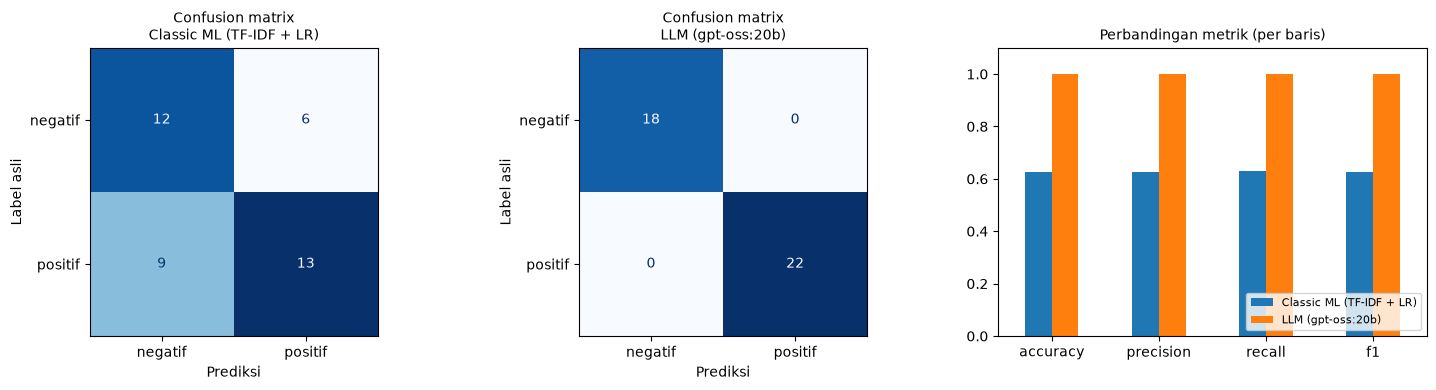

In [17]:
n_models = len(pred_cols)
fig, axes = plt.subplots(1, n_models + 1, figsize=(5 * (n_models + 1), 4))

for ax, (name, col) in zip(axes[:n_models], pred_cols.items()):
    cm = confusion_matrix(test_df["sentiment"], test_df[col], labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix\n{name}", fontsize=10)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label asli")

metrics = ["accuracy", "precision", "recall", "f1"]
bar_df = comparison[comparison["level"] == "per baris"].set_index("pendekatan")[metrics]
bar_df.T.plot(kind="bar", ax=axes[-1], ylim=(0, 1.1), rot=0)
axes[-1].set_title("Perbandingan metrik (per baris)", fontsize=10)
axes[-1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig(DOC_DIR / "model_comparison_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### Analisis kesalahan prediksi
Melihat contoh kalimat yang salah ditebak itu lebih berguna daripada hanya melihat angka: dari situ kelihatan **kenapa** model salah.

In [18]:
for name, col in pred_cols.items():
    salah = test_df[test_df[col] != test_df["sentiment"]]
    print(f"{name}: {len(salah)} baris salah ({salah['review_text'].nunique()} teks unik)")
    if len(salah):
        display(salah[["review_text", "sentiment", col]].drop_duplicates("review_text"))
    print()

Classic ML (TF-IDF + LR): 15 baris salah (2 teks unik)


,review_text,sentiment,classic_pred
5,"Bahan murahan, tidak sesuai dengan harga yang ...",negatif,positif
8,"Produknya rapi dan bersih, tidak ada cacat sam...",positif,negatif



LLM (gpt-oss:20b): 0 baris salah (0 teks unik)



### Perbandingan kecepatan

In [19]:
speed = {"Classic ML (TF-IDF + LR)": {"waktu_training_detik": round(classic_train_s, 3),
                                     "inferensi_ms_per_ulasan": round(classic_infer_ms, 3)}}
if LLM_AVAILABLE:
    real_calls = llm_df.loc[~llm_df["reused"].astype(bool), "latency_s"]
    speed[f"LLM ({OLLAMA_MODEL})"] = {"waktu_training_detik": 0,
                                      "inferensi_ms_per_ulasan": round(real_calls.mean() * 1000, 1)}
speed_df = pd.DataFrame(speed).T
display(speed_df)
speed_df.to_csv(RESULTS_DIR / "speed_summary.csv")

,waktu_training_detik,inferensi_ms_per_ulasan
Classic ML (TF-IDF + LR),0.007,0.034
LLM (gpt-oss:20b),0.000,2667.600


## 6. Analisis Trade-off & Limitation


**a. Performa (metrik evaluasi)**

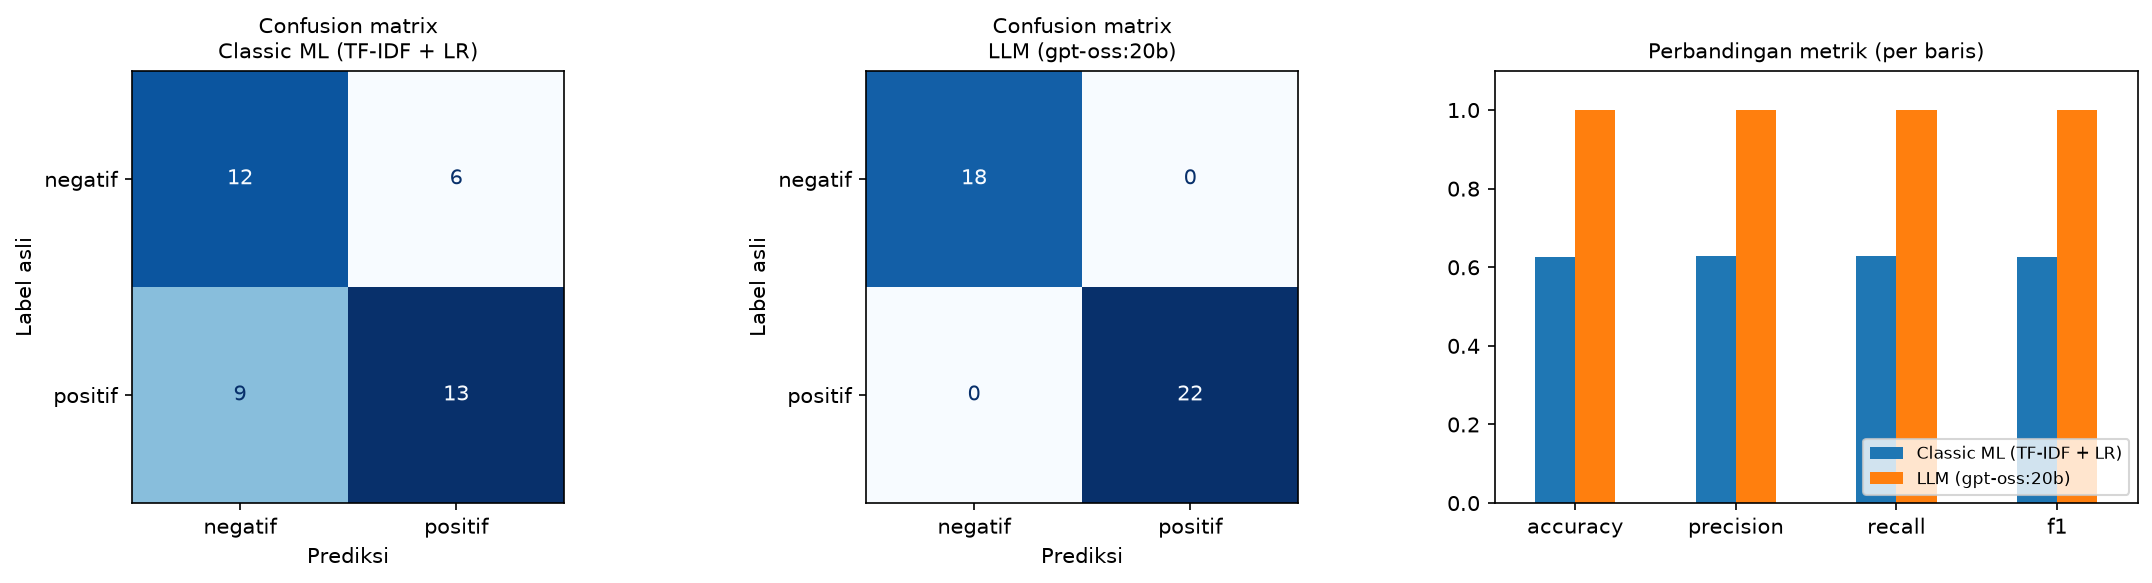

| Aspek | Classic ML (TF-IDF + LR) | LLM (`gpt-oss:20b` via Ollama) |
|---|---|---|
| Performa (data ini) | Accuracy 0.625, F1 0.625 | Accuracy 1.000, F1 1.000 |
| Effort implementasi | Butuh data berlabel, training, dan pipeline; pipeline sendiri ringan | Tanpa training, cukup prompt (6 contoh); tetapi butuh Ollama dan model sekitar 13-14 GB |
| Kecepatan | ~0,034 ms per ulasan; training ~0,007 detik | ~2,7 detik per ulasan (sekitar 78.000x lebih lambat) |
| Biaya | Hampir nol, cukup CPU biasa | Lokal: tanpa biaya per-token, tetapi butuh RAM/GPU besar, listrik, dan maintenance. API berbayar: biaya per token (lihat 6.3) |
| Kebutuhan data | Butuh teks yang beragam; dengan hanya 32 teks unik hasilnya lemah dan tidak stabil | Beberapa contoh sudah cukup |  

**b. Trade-off implementasi, kecepatan, dan biaya**
- *Effort:* Classic ML perlu data berlabel dan proses training. LLM tidak perlu training, cukup prompt.
- *Kecepatan:* bandingkan tabel kecepatan di atas (ms per ulasan).
- *Biaya:* Ollama berjalan lokal (tanpa biaya per-token) tapi butuh hardware besar. Bandingkan dengan estimasi biaya API berbayar untuk volume ulasan produksi.

**c. Limitation**
- **Data:** hanya 40 teks unik dengan kalimat bergaya template, dan test set hanya 8 teks unik. Hasil belum tentu berlaku untuk ulasan nyata (sarkasme, campur bahasa, ulasan netral atau campuran).
- **Perbandingan ini menguntungkan LLM** karena data latih Classic ML sangat sedikit. Dengan data yang jauh lebih banyak dan beragam, Classic ML kemungkinan membaik; hasil ini bukan bukti bahwa LLM selalu lebih baik.
- **LLM:** lambat, butuh hardware besar, hasil dapat berbeda antar versi model/hardware meskipun `temperature=0`, dan format jawaban harus divalidasi (pada eksperimen ini 0 jawaban `invalid` dari 40).
- **Evaluasi LLM** dilakukan sekali pada satu test set dengan satu desain prompt; variasi prompt belum diuji.
- Hanya 2 kelas, ulasan pendek, tanpa sarkasme.

## 7. Rekomendasi Technical Approach

**Rekomendasi: kembangkan pendekatan LLM (few-shot prompting) sebagai pendekatan utama pada tahap awal**, dengan klasifikasi dilakukan **secara asinkron saat ulasan masuk** dan hasilnya disimpan.

**Alasan:**
1. **Performa lebih baik pada test set yang sama** (F1 1.000 vs 0.625), termasuk pada kalimat bernegasi yang membuat Classic ML salah.
2. **Data berlabel terbatas.** Hanya ada 32 teks unik untuk training sehingga Classic ML tidak stabil (CV std ≈ 0.2). LLM tidak butuh training dan cukup dengan 6 contoh.
3. **Kelemahan utama LLM (latency ~2,7 detik per ulasan) tidak menghalangi fitur ini** bila klasifikasi dilakukan sekali saat ulasan dibuat, bukan setiap halaman produk dibuka.
4. **Biaya per ulasan kecil** karena prompt pendek (~240-280 token input, output satu kata).